In [2]:
import re
import os
import sys
import pandas as pd
from plotnine import *
from datetime import datetime

In [3]:
colors = {"A1":"red",
         "A2":"orange",
         "A3 (new longs)" : "yellow",
         "B3.2":"blue",
         "B3.6":"green",
         "C2.1":"purple",
         "D1.1":"brown"
         }

In [4]:
def fractional_year_to_datetime(year_fraction):
    year = int(year_fraction)
    remainder = year_fraction - year
    start = datetime.datetime(year, 1, 1)
    end = datetime.datetime(year + 1, 1, 1)
    return start + (end - start) * remainder

In [5]:
# Part 1: Weighted Lineage Dispersal Velocity

In [6]:
velocity = pd.read_excel("../H5-genotypes/Plotting/dispersal_velocity/genotype_WLDV.xlsx", header = 1)

In [7]:
print(velocity)

         Genotype  Low 95% HPD    Median  High 95% HPD
0              A1     3519.742  3922.804      4361.811
1              A2     1472.606  1819.703      2173.872
2  A3 (new longs)     2903.120  3647.468      4488.153
3            B3.2     4724.206  5330.909      6898.785
4            B3.6     2546.543  3259.109      3910.403
5            C2.1     1884.613  2312.950      2748.745
6            D1.1     1312.661  2387.941      3366.054


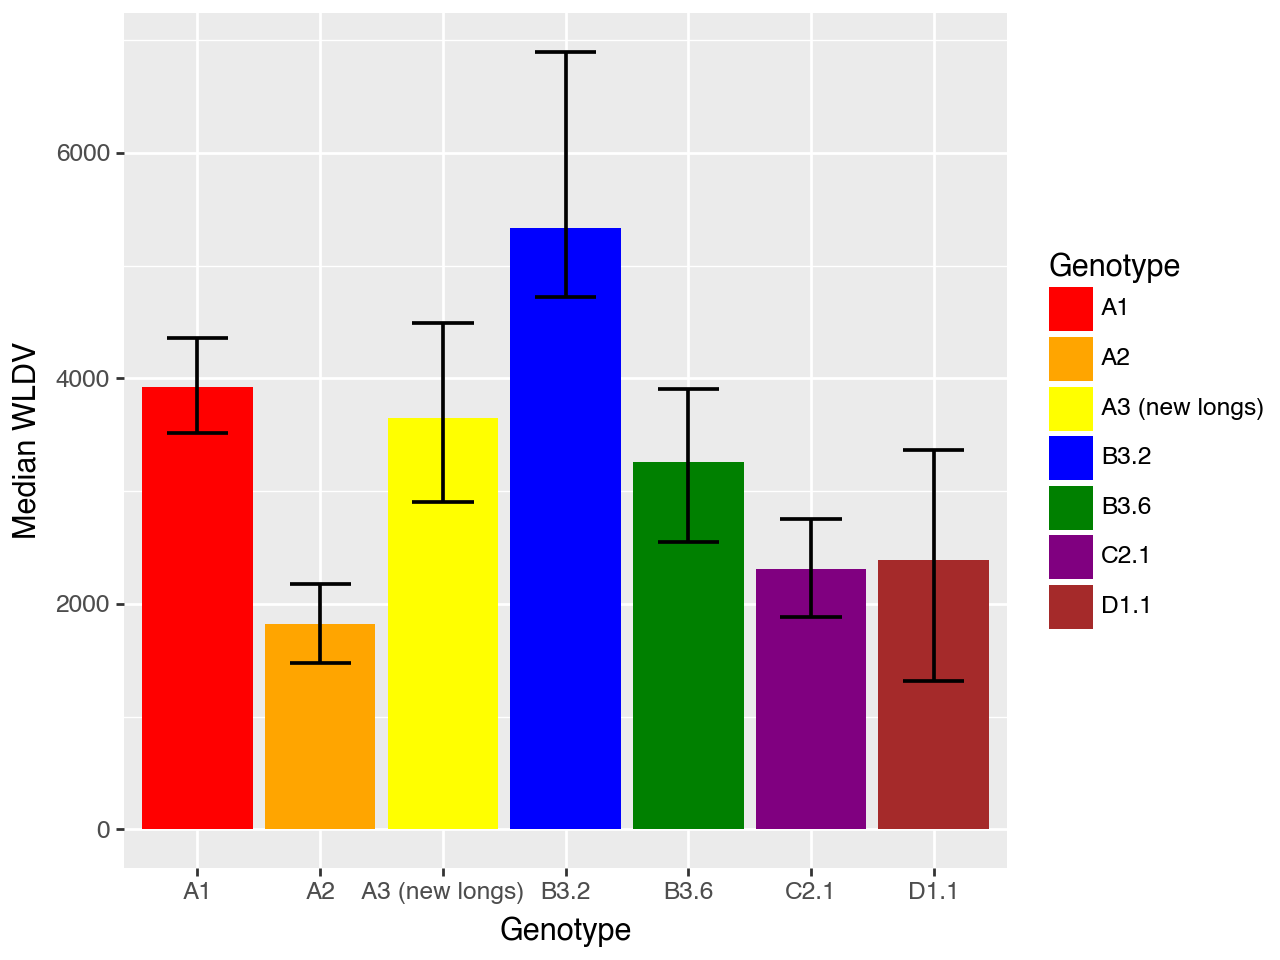

In [9]:
velocity_plot = (
    ggplot(velocity, aes(x = "Genotype", y = "Median", fill = "Genotype"))
    + geom_bar(stat = "identity")
    + geom_errorbar(aes(x = "Genotype", ymax = "High 95% HPD", ymin = "Low 95% HPD"), data = velocity, color = "black", size = 0.75, linetype = "solid")
    + scale_fill_manual(colors)
    + labs(x = "Genotype", y = "Median WLDV")
)

velocity_plot.show()

In [26]:
# Part two: Spatial wavefront

In [131]:
med_wavefront_A1 = pd.read_csv("../H5-genotypes/Plotting/spatial_wavefront/h5_A1_contphyl_median_spatial_wavefront_distance.txt", sep = "\t")
med_wavefront_A2 = pd.read_csv("../H5-genotypes/Plotting/spatial_wavefront/h5_A2_contphyl_median_spatial_wavefront_distance.txt", sep = "\t")
med_wavefront_A3 = pd.read_csv("../H5-genotypes/Plotting/spatial_wavefront/h5_A3_contphyl_new-longs_median_spatial_wavefront_distance.txt", sep = "\t")
med_wavefront_B32 = pd.read_csv("../H5-genotypes/Plotting/spatial_wavefront/h5_B3.2_contphyl_median_spatial_wavefront_distance.txt", sep = "\t")
med_wavefront_B36 = pd.read_csv("../H5-genotypes/Plotting/spatial_wavefront/h5_B3.6_contphyl_exponential_median_spatial_wavefront_distance.txt", sep = "\t")
med_wavefront_C21 = pd.read_csv("../H5-genotypes/Plotting/spatial_wavefront/h5_C2.1_contphyl_median_spatial_wavefront_distance.txt", sep = "\t")
med_wavefront_D11 = pd.read_csv("../H5-genotypes/Plotting/spatial_wavefront/h5_D1.1_contphyl_median_spatial_wavefront_distance.txt", sep = "\t")

In [132]:
med_wavefront_A1["genotype"] = "A1"
med_wavefront_A2["genotype"] = "A2"
med_wavefront_A3["genotype"] = "A3 (new longs)"
med_wavefront_B32["genotype"] = "B3.2"
med_wavefront_B36["genotype"] = "B3.6"
med_wavefront_C21["genotype"] = "C2.1"
med_wavefront_D11["genotype"] = "D1.1"

In [133]:
merged_med_wavefront = pd.concat([med_wavefront_A1, med_wavefront_A2, med_wavefront_A3, med_wavefront_B32, med_wavefront_B36, med_wavefront_C21, med_wavefront_D11])
# merged_med_wavefront = pd.concat([med_wavefront_B32, med_wavefront_B36, med_wavefront_C21, med_wavefront_D11])

In [134]:
hpd_wavefront_A1 = pd.read_csv("../H5-genotypes/Plotting/spatial_wavefront/h5_A1_contphyl_95%HPD_spatial_wavefront_distance.txt", sep = "\t")
hpd_wavefront_A2 = pd.read_csv("../H5-genotypes/Plotting/spatial_wavefront/h5_A2_contphyl_95%HPD_spatial_wavefront_distance.txt", sep = "\t")
hpd_wavefront_A3 = pd.read_csv("../H5-genotypes/Plotting/spatial_wavefront/h5_A3_contphyl_new-longs_95%HPD_spatial_wavefront_distance.txt", sep = "\t")
hpd_wavefront_B32 = pd.read_csv("../H5-genotypes/Plotting/spatial_wavefront/h5_B3.2_contphyl_95%HPD_spatial_wavefront_distance.txt", sep = "\t")
hpd_wavefront_B36 = pd.read_csv("../H5-genotypes/Plotting/spatial_wavefront/h5_B3.6_contphyl_exponential_95%HPD_spatial_wavefront_distance.txt", sep = "\t")
hpd_wavefront_C21 = pd.read_csv("../H5-genotypes/Plotting/spatial_wavefront/h5_C2.1_contphyl_95%HPD_spatial_wavefront_distance.txt", sep = "\t")
hpd_wavefront_D11 = pd.read_csv("../H5-genotypes/Plotting/spatial_wavefront/h5_D1.1_contphyl_95%HPD_spatial_wavefront_distance.txt", sep = "\t")

In [135]:
hpd_wavefront_A1["genotype"] = "A1"
hpd_wavefront_A2["genotype"] = "A2"
hpd_wavefront_A3["genotype"] = "A3 (new longs)"
hpd_wavefront_B32["genotype"] = "B3.2"
hpd_wavefront_B36["genotype"] = "B3.6"
hpd_wavefront_C21["genotype"] = "C2.1"
hpd_wavefront_D11["genotype"] = "D1.1"

In [136]:
merged_hpd_wavefront = pd.concat([hpd_wavefront_A1, hpd_wavefront_A2, hpd_wavefront_A3, hpd_wavefront_B32, hpd_wavefront_B36, hpd_wavefront_C21, hpd_wavefront_D11])
# merged_hpd_wavefront = pd.concat([hpd_wavefront_B32, hpd_wavefront_B36, hpd_wavefront_C21, hpd_wavefront_D11])

In [137]:
#merged_med_wavefront["time"] = merged_med_wavefront["time"].apply(fractional_year_to_datetime)
# merged_hpd_wavefront["time"] = merged_hpd_wavefront["time"].apply(fractional_year_to_datetime)

In [138]:
for i in set(merged_med_wavefront["genotype"]):
    if i in colors:
        print("yes")
    else:
        print(i)

yes
yes
yes
yes
yes
yes
yes


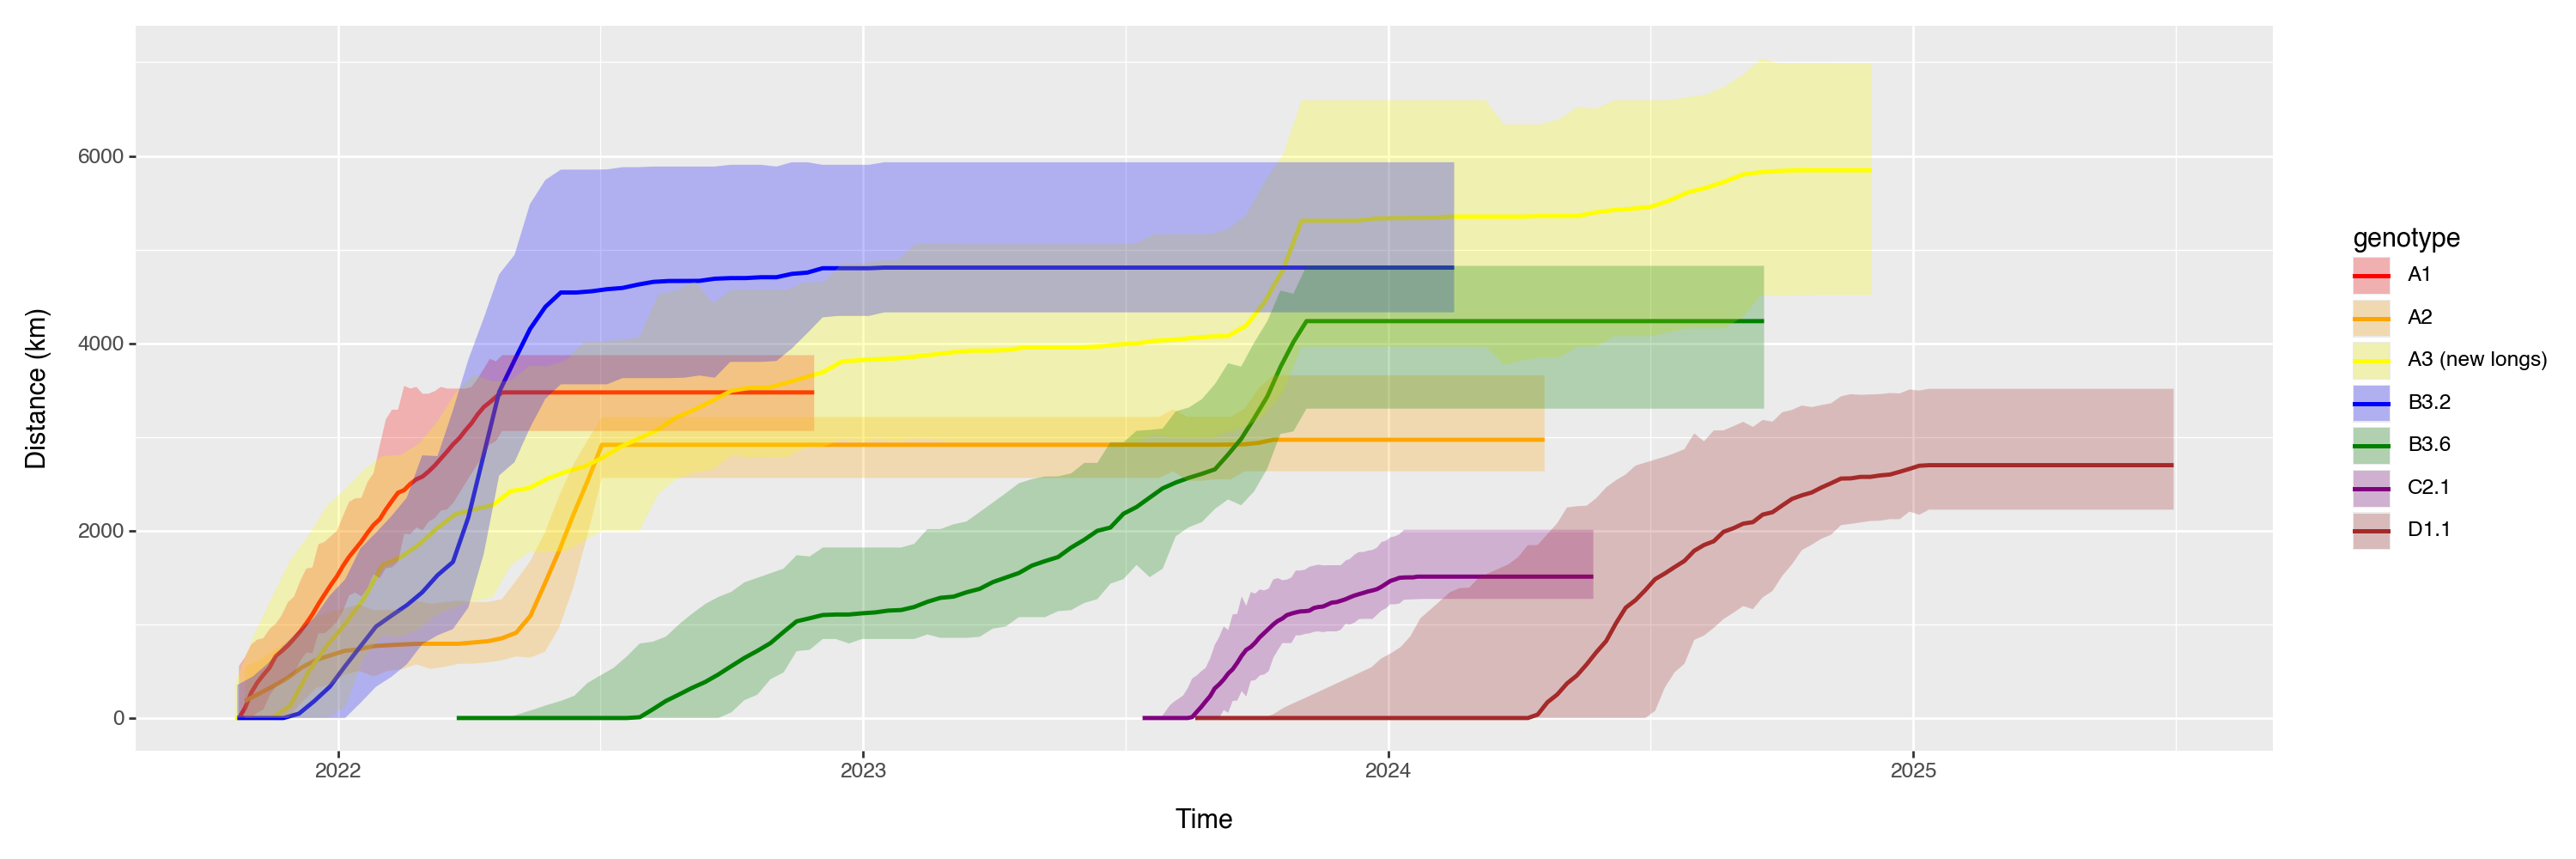

In [140]:
wavefront_plot = (
    ggplot()
    + geom_line(aes(x="time", y="distance", color = "genotype"), data = merged_med_wavefront, size = 1)
    + geom_ribbon(aes(x = "time", ymin = "95%HPD_lower_value", ymax = "95%HPD_higher_value", fill = "genotype"), data = merged_hpd_wavefront, alpha = 0.25)
    + scale_color_manual(colors)
    + scale_fill_manual(colors)
    + xlim(2021.8, 2025.5)
    + labs(x = "Time", y = "Distance (km)")
    + theme(figure_size = (15, 5))
)

wavefront_plot.show()

In [107]:
# Part three: WDC

In [109]:
med_wdc_A1 = pd.read_csv("../H5-genotypes/Plotting/weighted_diffusion_coefficient/h5_A1_contphyl_median_weighted_diffusion_coefficient.txt", sep = "\t")
med_wdc_A2 = pd.read_csv("../H5-genotypes/Plotting/weighted_diffusion_coefficient/h5_A2_contphyl_median_weighted_diffusion_coefficient.txt", sep = "\t")
med_wdc_A3 = pd.read_csv("../H5-genotypes/Plotting/weighted_diffusion_coefficient/h5_A3_contphyl_new-longs_median_weighted_diffusion_coefficient.txt", sep = "\t")
med_wdc_B32 = pd.read_csv("../H5-genotypes/Plotting/weighted_diffusion_coefficient/h5_B3.2_contphyl_median_weighted_diffusion_coefficient.txt", sep = "\t")
med_wdc_B36 = pd.read_csv("../H5-genotypes/Plotting/weighted_diffusion_coefficient/h5_B3.6_contphyl_exponential_median_weighted_diffusion_coefficient.txt", sep = "\t")
med_wdc_C21 = pd.read_csv("../H5-genotypes/Plotting/weighted_diffusion_coefficient/h5_C2.1_contphyl_median_weighted_diffusion_coefficient.txt", sep = "\t")
med_wdc_D11 = pd.read_csv("../H5-genotypes/Plotting/weighted_diffusion_coefficient/h5_D1.1_contphyl_median_weighted_diffusion_coefficient.txt", sep = "\t")

In [110]:
med_wdc_A1["genotype"] = "A1"
med_wdc_A2["genotype"] = "A2"
med_wdc_A3["genotype"] = "A3 (new longs)"
med_wdc_B32["genotype"] = "B3.2"
med_wdc_B36["genotype"] = "B3.6"
med_wdc_C21["genotype"] = "C2.1"
med_wdc_D11["genotype"] = "D1.1"

In [120]:
merged_med_wdc = pd.concat([med_wdc_A1, med_wdc_A2, med_wdc_A3, med_wdc_B32, med_wdc_B36, med_wdc_C21, med_wdc_D11])
# merged_med_wdc = pd.concat([med_wavefront_B32, med_wavefront_B36, med_wavefront_C21, med_wavefront_D11])

In [121]:
hpd_wdc_A1 = pd.read_csv("../H5-genotypes/Plotting/weighted_diffusion_coefficient/h5_A1_contphyl_95%HPD_weighted_diffusion_coefficient.txt", sep = "\t")
hpd_wdc_A2 = pd.read_csv("../H5-genotypes/Plotting/weighted_diffusion_coefficient/h5_A2_contphyl_95%HPD_weighted_diffusion_coefficient.txt", sep = "\t")
hpd_wdc_A3 = pd.read_csv("../H5-genotypes/Plotting/weighted_diffusion_coefficient/h5_A3_contphyl_new-longs_95%HPD_weighted_diffusion_coefficient.txt", sep = "\t")
hpd_wdc_B32 = pd.read_csv("../H5-genotypes/Plotting/weighted_diffusion_coefficient/h5_B3.2_contphyl_95%HPD_weighted_diffusion_coefficient.txt", sep = "\t")
hpd_wdc_B36 = pd.read_csv("../H5-genotypes/Plotting/weighted_diffusion_coefficient/h5_B3.6_contphyl_exponential_95%HPD_weighted_diffusion_coefficient.txt", sep = "\t")
hpd_wdc_C21 = pd.read_csv("../H5-genotypes/Plotting/weighted_diffusion_coefficient/h5_C2.1_contphyl_95%HPD_weighted_diffusion_coefficient.txt", sep = "\t")
hpd_wdc_D11 = pd.read_csv("../H5-genotypes/Plotting/weighted_diffusion_coefficient/h5_D1.1_contphyl_95%HPD_weighted_diffusion_coefficient.txt", sep = "\t")

In [122]:
hpd_wdc_A1["genotype"] = "A1"
hpd_wdc_A2["genotype"] = "A2"
hpd_wdc_A3["genotype"] = "A3 (new longs)"
hpd_wdc_B32["genotype"] = "B3.2"
hpd_wdc_B36["genotype"] = "B3.6"
hpd_wdc_C21["genotype"] = "C2.1"
hpd_wdc_D11["genotype"] = "D1.1"

In [123]:
merged_hpd_wdc = pd.concat([hpd_wdc_A1, hpd_wdc_A2, hpd_wdc_A3, hpd_wdc_B32, hpd_wdc_B36, hpd_wdc_C21, hpd_wdc_D11])
# merged_hpd_wdc = pd.concat([hpd_wavefront_B32, hpd_wavefront_B36, hpd_wavefront_C21, hpd_wavefront_D11])

In [124]:
#merged_med_wavefront["time"] = merged_med_wavefront["time"].apply(fractional_year_to_datetime)
# merged_hpd_wavefront["time"] = merged_hpd_wavefront["time"].apply(fractional_year_to_datetime)

In [125]:
print(merged_med_wdc.columns)

Index(['time', 'diffusion_coefficient', 'number_of_branches', 'genotype'], dtype='object')


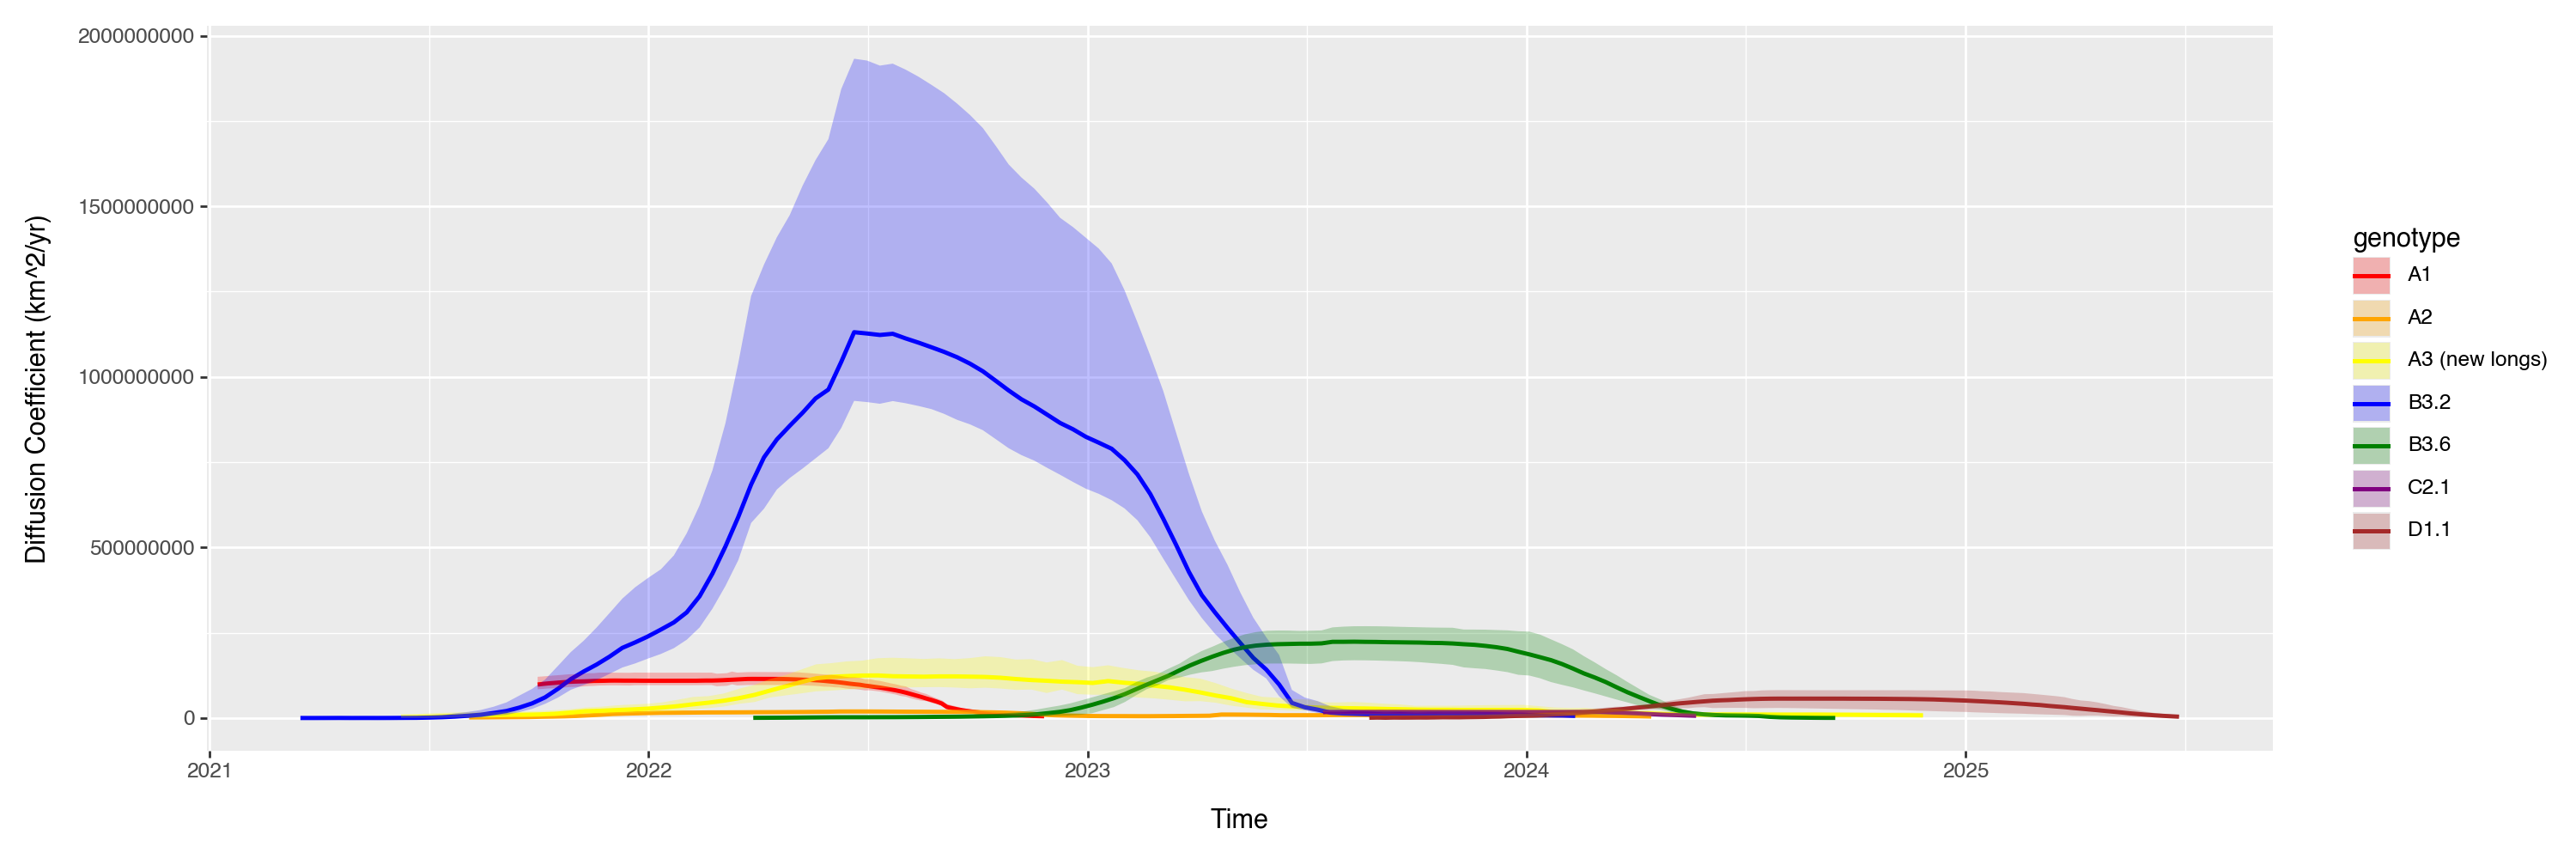

In [142]:
diffusion_plot = (
    ggplot()
    + geom_line(aes(x="time", y="diffusion_coefficient", color = "genotype"), data = merged_med_wdc, size = 1)
    + geom_ribbon(aes(x = "time", ymin = "95%HPD_lower_value", ymax = "95%HPD_higher_value", fill = "genotype"), data = merged_hpd_wdc, alpha = 0.25)
    + scale_color_manual(colors)
    + scale_fill_manual(colors)
    # + scale_y_log10()
    + labs(x = "Time", y = "Diffusion Coefficient (km^2/yr)")
    + theme(figure_size = (15, 5))
)

diffusion_plot.show()